In [ ]:
# Exercise 1: Create agents and tasks

agents = ["Agent A", "Agent B", "Agent C"]

tasks = {
    "T1": {
        "location": "Zone 1",
        "bids": {
            "Agent A": {"cost": 100, "time": 20},
            "Agent B": {"cost": 120, "time": 25},
            "Agent C": {"cost": 110, "time": 22}
        }
    },
    "T2": {
        "location": "Zone 2",
        "bids": {
            "Agent A": {"cost": 150, "time": 30},
            "Agent B": {"cost": 130, "time": 25},
            "Agent C": {"cost": 140, "time": 28}
        }
    },
    "T3": {
        "location": "Zone 1",
        "bids": {
            "Agent A": {"cost": 90, "time": 18},
            "Agent B": {"cost": 100, "time": 20},
            "Agent C": {"cost": 85, "time": 17}
        }
    },
    "T4": {
        "location": "Zone 3",
        "bids": {
            "Agent A": {"cost": 200, "time": 40},
            "Agent B": {"cost": 180, "time": 35},
            "Agent C": {"cost": 190, "time": 38}
        }
    },
    "T5": {
        "location": "Zone 2",
        "bids": {
            "Agent A": {"cost": 120, "time": 25},
            "Agent B": {"cost": 110, "time": 22},
            "Agent C": {"cost": 115, "time": 24}
        }
    },
    "T6": {
        "location": "Zone 4",
        "bids": {
            "Agent A": {"cost": 160, "time": 32},
            "Agent B": {"cost": 170, "time": 34},
            "Agent C": {"cost": 145, "time": 28}
        }
    }
}

print("Manager Agent created.")
print("Delivery agents:", agents)
print("Total delivery tasks:", len(tasks))

print("\nTask locations:")
for task_id, task in tasks.items():
    print(f"{task_id}: {task['location']}")

Manager Agent created.
Delivery agents: ['Agent A', 'Agent B', 'Agent C']
Total delivery tasks: 6

Task locations:
T1: Zone 1
T2: Zone 2
T3: Zone 1
T4: Zone 3
T5: Zone 2
T6: Zone 4


In [ ]:
# Exercise 2: PGP conflict detection and resolution

# Each plan contains:
# (agent, task, shared_resource, time_slot)

local_plans = [
    ("Agent A", "T1", "Loading Dock 1", "10:00"),
    ("Agent B", "T3", "Loading Dock 1", "10:00"),
    ("Agent C", "T6", "Loading Dock 2", "10:00"),
    ("Agent A", "T2", "Loading Dock 2", "10:30")
]

def detect_conflicts(plans):
    occupied = {}
    conflicts = []

    for index, plan in enumerate(plans):
        agent, task, resource, time_slot = plan
        key = (resource, time_slot)

        if key in occupied:
            previous = occupied[key]
            if previous[0] != agent:
                conflicts.append((previous, plan, index))
        else:
            occupied[key] = plan

    return conflicts


print("Initial local plans:")
for plan in local_plans:
    print(plan)

conflicts = detect_conflicts(local_plans)

print("\nDetected conflicts:")
if conflicts:
    for first, second, _ in conflicts:
        print(
            f"{first[0]} and {second[0]} both use "
            f"{first[2]} at {first[3]}"
        )
else:
    print("No conflicts found.")

# Resolve conflicts by rescheduling the second agent
for first, second, index in conflicts:
    agent, task, resource, old_time = second
    local_plans[index] = (agent, task, resource, "10:15")

print("\nPlans after PGP coordination:")
for plan in local_plans:
    print(plan)

print("\nRemaining conflicts:", len(detect_conflicts(local_plans)))

Initial local plans:
('Agent A', 'T1', 'Loading Dock 1', '10:00')
('Agent B', 'T3', 'Loading Dock 1', '10:00')
('Agent C', 'T6', 'Loading Dock 2', '10:00')
('Agent A', 'T2', 'Loading Dock 2', '10:30')

Detected conflicts:
Agent A and Agent B both use Loading Dock 1 at 10:00

Plans after PGP coordination:
('Agent A', 'T1', 'Loading Dock 1', '10:00')
('Agent B', 'T3', 'Loading Dock 1', '10:15')
('Agent C', 'T6', 'Loading Dock 2', '10:00')
('Agent A', 'T2', 'Loading Dock 2', '10:30')

Remaining conflicts: 0


In [ ]:
# Exercise 3: Contract Net Protocol

def allocate_tasks(tasks, verbose=True):
    allocation = {}
    agent_totals = {
        agent: {"cost": 0, "time": 0, "tasks": []}
        for agent in agents
    }

    for task_id, task in tasks.items():

        # Step 1: Task announcement
        if verbose:
            print(f"\n{'=' * 45}")
            print(f"ANNOUNCEMENT: Task {task_id}")
            print(f"Location: {task['location']}")

        # Step 2: Collect bids
        bids = task["bids"]

        if verbose:
            print("Bids received:")

            for agent, bid in bids.items():
                print(
                    f"  {agent}: Cost={bid['cost']}, "
                    f"Time={bid['time']} minutes"
                )

        # Step 3 and 4: Compare bids and select winner
        # Minimize cost; if tied, minimize time.
        selected_agent = min(
            bids,
            key=lambda agent: (
                bids[agent]["cost"],
                bids[agent]["time"]
            )
        )

        winning_bid = bids[selected_agent]

        # Step 5: Assignment
        allocation[task_id] = {
            "agent": selected_agent,
            "cost": winning_bid["cost"],
            "time": winning_bid["time"]
        }

        agent_totals[selected_agent]["cost"] += winning_bid["cost"]
        agent_totals[selected_agent]["time"] += winning_bid["time"]
        agent_totals[selected_agent]["tasks"].append(task_id)

        if verbose:
            print(
                f"SELECTED: {selected_agent} "
                f"(Cost={winning_bid['cost']}, "
                f"Time={winning_bid['time']} min)"
            )
            print(f"ASSIGNED: {task_id} -> {selected_agent}")

    return allocation, agent_totals


allocation, agent_totals = allocate_tasks(tasks)

print("\nCNP completed successfully!")


ANNOUNCEMENT: Task T1
Location: Zone 1
Bids received:
  Agent A: Cost=100, Time=20 minutes
  Agent B: Cost=120, Time=25 minutes
  Agent C: Cost=110, Time=22 minutes
SELECTED: Agent A (Cost=100, Time=20 min)
ASSIGNED: T1 -> Agent A

ANNOUNCEMENT: Task T2
Location: Zone 2
Bids received:
  Agent A: Cost=150, Time=30 minutes
  Agent B: Cost=130, Time=25 minutes
  Agent C: Cost=140, Time=28 minutes
SELECTED: Agent B (Cost=130, Time=25 min)
ASSIGNED: T2 -> Agent B

ANNOUNCEMENT: Task T3
Location: Zone 1
Bids received:
  Agent A: Cost=90, Time=18 minutes
  Agent B: Cost=100, Time=20 minutes
  Agent C: Cost=85, Time=17 minutes
SELECTED: Agent C (Cost=85, Time=17 min)
ASSIGNED: T3 -> Agent C

ANNOUNCEMENT: Task T4
Location: Zone 3
Bids received:
  Agent A: Cost=200, Time=40 minutes
  Agent B: Cost=180, Time=35 minutes
  Agent C: Cost=190, Time=38 minutes
SELECTED: Agent B (Cost=180, Time=35 min)
ASSIGNED: T4 -> Agent B

ANNOUNCEMENT: Task T5
Location: Zone 2
Bids received:
  Agent A: Cost=120,

In [ ]:
# Exercise 4: Display final allocation

print("\nFINAL TASK ALLOCATION")
print("-" * 55)
print(f"{'Task':<10}{'Selected Agent':<20}{'Cost':<10}{'Time (min)':<10}")
print("-" * 55)

for task_id, result in allocation.items():
    print(
        f"{task_id:<10}"
        f"{result['agent']:<20}"
        f"{result['cost']:<10}"
        f"{result['time']:<10}"
    )

total_cost = sum(result["cost"] for result in allocation.values())
total_time = sum(result["time"] for result in allocation.values())

print("-" * 55)
print(f"Total cost: {total_cost}")
print(f"Total assigned time: {total_time} minutes")

print("\nAGENT-WISE SUMMARY")
for agent, info in agent_totals.items():
    print(
        f"{agent}: Tasks={info['tasks']}, "
        f"Cost={info['cost']}, "
        f"Time={info['time']} minutes"
    )


FINAL TASK ALLOCATION
-------------------------------------------------------
Task      Selected Agent      Cost      Time (min)
-------------------------------------------------------
T1        Agent A             100       20        
T2        Agent B             130       25        
T3        Agent C             85        17        
T4        Agent B             180       35        
T5        Agent B             110       22        
T6        Agent C             145       28        
-------------------------------------------------------
Total cost: 750
Total assigned time: 147 minutes

AGENT-WISE SUMMARY
Agent A: Tasks=['T1'], Cost=100, Time=20 minutes
Agent B: Tasks=['T2', 'T4', 'T5'], Cost=420, Time=82 minutes
Agent C: Tasks=['T3', 'T6'], Cost=230, Time=45 minutes


In [ ]:
# Exercise 5: Modify inputs and rerun CNP

import copy

# Save the original allocation and totals for comparison
original_allocation = copy.deepcopy(allocation)
original_totals = copy.deepcopy(agent_totals)

# Create modified input data without changing the original
modified_tasks = copy.deepcopy(tasks)

# Agent A submits more competitive bids
modified_tasks["T2"]["bids"]["Agent A"] = {
    "cost": 100, "time": 20
}

modified_tasks["T4"]["bids"]["Agent A"] = {
    "cost": 160, "time": 30
}

modified_tasks["T5"]["bids"]["Agent A"] = {
    "cost": 90, "time": 18
}

print("Modified bids:")
for task_id in ["T2", "T4", "T5"]:
    print(
        f"{task_id}: Agent A -> "
        f"Cost={modified_tasks[task_id]['bids']['Agent A']['cost']}, "
        f"Time={modified_tasks[task_id]['bids']['Agent A']['time']} min"
    )

# Rerun CNP
modified_allocation, modified_totals = allocate_tasks(
    modified_tasks,
    verbose=False
)

print("\nMODIFIED TASK ALLOCATION")
print("-" * 55)
print(f"{'Task':<10}{'Selected Agent':<20}{'Cost':<10}{'Time (min)':<10}")
print("-" * 55)

for task_id, result in modified_allocation.items():
    print(
        f"{task_id:<10}"
        f"{result['agent']:<20}"
        f"{result['cost']:<10}"
        f"{result['time']:<10}"
    )

new_total_cost = sum(
    result["cost"] for result in modified_allocation.values()
)
new_total_time = sum(
    result["time"] for result in modified_allocation.values()
)

print("-" * 55)
print(f"Modified total cost: {new_total_cost}")
print(f"Modified total time: {new_total_time} minutes")

print("\nCHANGE IN OVERALL RESULTS")
print("Cost change:", new_total_cost - total_cost)
print("Time change:", new_total_time - total_time, "minutes")

Modified bids:
T2: Agent A -> Cost=100, Time=20 min
T4: Agent A -> Cost=160, Time=30 min
T5: Agent A -> Cost=90, Time=18 min

MODIFIED TASK ALLOCATION
-------------------------------------------------------
Task      Selected Agent      Cost      Time (min)
-------------------------------------------------------
T1        Agent A             100       20        
T2        Agent A             100       20        
T3        Agent C             85        17        
T4        Agent A             160       30        
T5        Agent A             90        18        
T6        Agent C             145       28        
-------------------------------------------------------
Modified total cost: 680
Modified total time: 133 minutes

CHANGE IN OVERALL RESULTS
Cost change: -70
Time change: -14 minutes


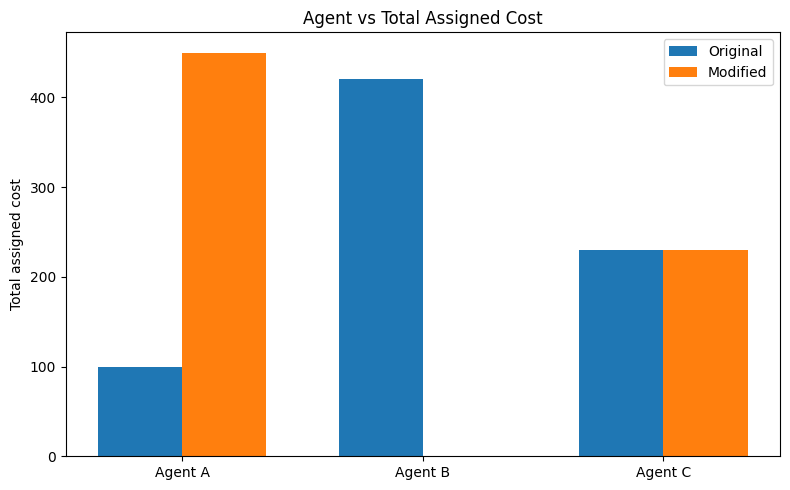

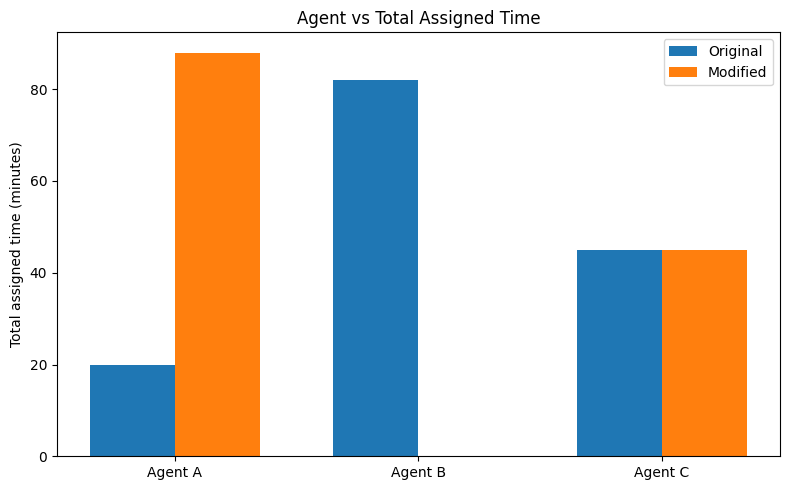

In [17]:
import matplotlib.pyplot as plt

agent_names = agents

original_costs = [
    original_totals[a]["cost"] for a in agent_names
]
modified_costs = [
    modified_totals[a]["cost"] for a in agent_names
]

original_times = [
    original_totals[a]["time"] for a in agent_names
]
modified_times = [
    modified_totals[a]["time"] for a in agent_names
]

x = list(range(len(agent_names)))
width = 0.35

# Graph 1: Assigned cost
plt.figure(figsize=(8, 5))

plt.bar(
    [i - width / 2 for i in x],
    original_costs,
    width,
    label="Original"
)

plt.bar(
    [i + width / 2 for i in x],
    modified_costs,
    width,
    label="Modified"
)

plt.xticks(x, agent_names)
plt.ylabel("Total assigned cost")
plt.title("Agent vs Total Assigned Cost")
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: Assigned time
plt.figure(figsize=(8, 5))

plt.bar(
    [i - width / 2 for i in x],
    original_times,
    width,
    label="Original"
)

plt.bar(
    [i + width / 2 for i in x],
    modified_times,
    width,
    label="Modified"
)

plt.xticks(x, agent_names)
plt.ylabel("Total assigned time (minutes)")
plt.title("Agent vs Total Assigned Time")
plt.legend()
plt.tight_layout()
plt.show()